In [2]:
! python -m pip install gurobipy
! python -m pip install networkx
! python -m pip install matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 80.6 MB/s  0:00:00


In [15]:
import networkx as nx

#  Definizione grafo orientato con NetworkX
G = nx.DiGraph()

## Aggiungi nodi
nodes = [
    ("A", {"bil": -1}),
    ("B", {"bil":  0}),
    ("C", {"bil":  0}),
    ("D", {"bil":  0}),
    ("E", {"bil":  0}),
    ("F", {"bil": +1})
]
G.add_nodes_from(nodes)

## Aggiungi archi (coda, testa, costo, consumo)
edges = [
    ("A","B", {"costo":  7, "consumo": 32}) ,
    ("A","C", {"costo":  8, "consumo": 14}) ,
    ("B","C", {"costo": -1, "consumo": 11}) ,
    ("B","D", {"costo":  4, "consumo": 10}) ,
    ("B","E", {"costo":  1, "consumo":  2}) ,
    ("B","F", {"costo":  5, "consumo": 14}) ,
    ("C","F", {"costo":  3, "consumo": 48}) ,
    ("D","F", {"costo":  1, "consumo": 33}) ,
    ("E","C", {"costo": -2, "consumo":  9}) ,
    ("E","D", {"costo":  0, "consumo": 14}) ,
    ("F","E", {"costo":  3, "consumo": 18})
]
G.add_edges_from(edges)

for v in G.nodes: # v è l'identificatore del nodo
  print(f"nodo {v} chiede {G.nodes[v]["bil"]}")
for (i,j) in G.edges: # (i,j) è l'identificatore dell'arco
  print(f"arco {i}->{j} costa {G.edges[i,j]["costo"]} e consuma {G[i][j]["consumo"]}")

nodo A chiede -1
nodo B chiede 0
nodo C chiede 0
nodo D chiede 0
nodo E chiede 0
nodo F chiede 1
arco A->B costa 7 e consuma 32
arco A->C costa 8 e consuma 14
arco B->C costa -1 e consuma 11
arco B->D costa 4 e consuma 10
arco B->E costa 1 e consuma 2
arco B->F costa 5 e consuma 14
arco C->F costa 3 e consuma 48
arco D->F costa 1 e consuma 33
arco E->C costa -2 e consuma 9
arco E->D costa 0 e consuma 14
arco F->E costa 3 e consuma 18


In [16]:
import gurobipy as gp
from gurobipy import GRB

#  Modello Gurobi
m = gp.Model("spW")

# Variabili (archi)
relax_integrality = False
x = m.addVars(G.edges, vtype = GRB.BINARY if not relax_integrality else GRB.CONTINUOUS, name="x")

# Vincoli di bilanciamento
for v in G.nodes:
  inflow  = gp.quicksum(x[i, v] for i in G.predecessors(v))
  outflow = gp.quicksum(x[v, j] for j in G.successors(v))
  m.addConstr(inflow - outflow == G.nodes[v]["bil"], name=f"balance[{v}]")

# Funzione obiettivo
m.setObjective(gp.quicksum(G.edges[i,j]["costo"] * x[i, j] for (i, j) in G.edges), GRB.MINIMIZE)

# *** LIMITE PESO COMPLESSIVO ***
W = 50
m.addConstr(gp.quicksum(G.edges[e]["consumo"] * x[e] for e in G.edges) <= W, name="ub_weight")
m.write("netflow.spW.lp")
m.optimize()


Gurobi Optimizer version 14.0.0 build v14.0.0rc1 (linux64 - "Ubuntu 24.04.5 LTS")

CPU model: Intel(R) Xeon(R) CPU @ 2.20GHz, instruction set [SSE2|AVX|AVX2]
Thread count: 1 physical cores, 2 logical processors, using up to 2 threads

Optimize a model with 7 rows, 11 columns and 33 nonzeros (Min)
Model fingerprint: 0xf3188d43
Model has 10 linear objective coefficients
Variable types: 0 continuous, 11 integer (11 binary)
Coefficient statistics:
  Matrix range     [1e+00, 5e+01]
  Objective range  [1e+00, 8e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 5e+01]

Found heuristic solution: objective 12.0000000
Presolve removed 7 rows and 11 columns
Presolve time: 0.00s
Presolve: All rows and columns removed

Explored 0 nodes (0 simplex iterations) in 0.01 seconds (0.00 work units)
Thread count was 1 (of 2 available processors)

Solution count 1: 12 

Optimal solution found (tolerance 1.00e-04)
Best objective 1.200000000000e+01, best bound 1.200000000000e+01, gap 0.0000%


In [17]:
#  Risultati
print("\n\nRisultati ottimizzazione:")
archi_in_soluzione = []
if m.status == GRB.OPTIMAL:
  m.setParam("OutputFlag",1)
  m.printAttr("x")
  print(f"Funzione obiettivo = {m.objVal:.6g}")
  used_weight = sum(G[i][j]["consumo"] * x[i,j].X for (i,j) in G.edges)
  print(f"Consumo complessivo = {used_weight} / {W}")
  print("\nArchi selezionati (x[i,j] == 1):")
  for (i, j) in G.edges:
    if x[i, j].X > 0.5:
      archi_in_soluzione.append((i, j))
      print(f"  {i} -> {j}")



Risultati ottimizzazione:
Set parameter OutputFlag to value 1

    Variable            x 
-------------------------
      x[A,B]            1 
      x[B,F]            1 
Funzione obiettivo = 12
Consumo complessivo = 46.0 / 50

Archi selezionati (x[i,j] == 1):
  A -> B
  B -> F


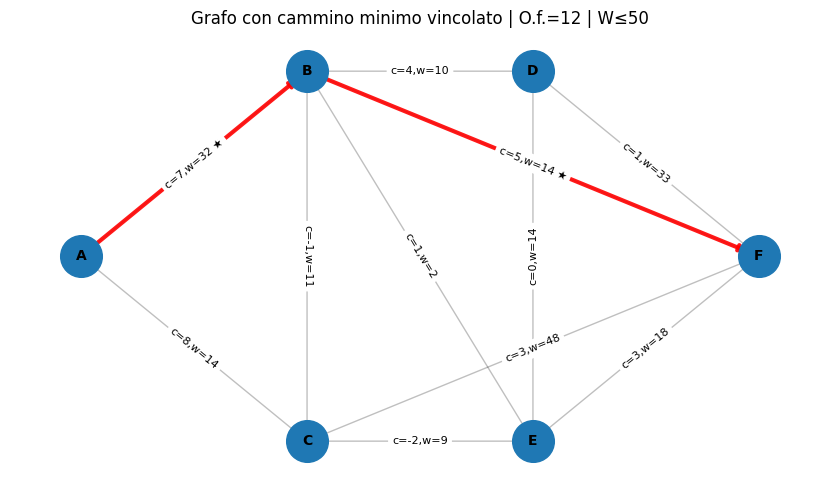

In [18]:
# Visualizzazione
import matplotlib.pyplot as plt

pos = {
    "A": (0, 2),
    "B": (1.5, 3),
    "C": (1.5, 1),
    "D": (3, 3),
    "E": (3, 1),
    "F": (4.5, 2),
}

plt.figure(figsize=(8.5, 5))

nx.draw_networkx_edges(G, pos, edgelist=list(G.edges), width=1.0, alpha=0.25, arrows=True)

if archi_in_soluzione:
    nx.draw_networkx_edges(G, pos, edgelist=archi_in_soluzione, width=3.0, alpha=0.9, arrows=True, edge_color="r")

nx.draw_networkx_nodes(G, pos, node_size=900)
nx.draw_networkx_labels(G, pos, font_size=10, font_weight="bold")

edge_labels = {}
for (i, j) in G.edges:
    cost = G[i][j]["costo"]
    weight = G[i][j]["consumo"]
    mark = " ★" if (i, j) in archi_in_soluzione else ""
    edge_labels[(i, j)] = f"c={cost},w={weight}{mark}"
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=8)

title = "Grafo con cammino minimo vincolato"
if m.status == GRB.OPTIMAL:
    title += f" | O.f.={m.objVal:.3g} | W≤{W}"
plt.title(title)
plt.axis("off")
plt.tight_layout()
plt.show()